Section A

In [0]:
df_entries = spark.table("tp_entries_raw")
df_attractions = spark.table("tp_attractions")
df_maintenance = spark.table("tp_maintenance")
df_changes = spark.table("tp_entry_changes")

display(df_entries)
display(df_attractions)
display(df_maintenance)
display(df_changes)

print(f"tp_entries_raw count: {df_entries.count()}")
print(f"tp_attractions count: {df_attractions.count()}")
print(f"tp_maintenance count: {df_maintenance.count()}")
print(f"tp_entry_changes count: {df_changes.count()}")

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


attraction_id,attraction_name,capacity_per_hour,category,features,is_active,location,min_height_cm,opened_year
A01,Sky Spinner,140,Thrill,"List(Outdoor, High Speed)",true,"List(N1, North)",120,2018
A02,Coral Carousel,200,Family,"List(Indoor, Family Friendly)",true,"List(E2, East)",0,2015
A03,Jungle Rapids,110,Water,"List(Water Ride, Outdoor)",true,"List(S1, South)",110,2020
A04,Moonlight Train,180,Family,"List(Scenic, Family Friendly)",true,"List(W3, West)",0,2012
A05,Meteor Drop,100,Thrill,"List(High Speed, Outdoor)",true,"List(N2, North)",135,2022
A06,Pirate Voyage,130,Water,"List(Water Ride, Themed)",true,"List(E1, East)",100,2019
A07,Crystal Maze,160,Adventure,"List(Indoor, Puzzle)",true,"List(S3, South)",90,2021
A08,Forest Flyers,120,Adventure,"List(Outdoor, Interactive)",true,"List(W1, West)",115,2023
A09,Galaxy Theater,260,Show,"List(Indoor, Live Show)",true,"List(N3, North)",0,2017
A10,Mini Explorers,190,Family,"List(Kids, Indoor)",true,"List(E3, East)",0,2016


maintenance_id,attraction_id,maintenance_date,issue_type,downtime_minutes,maintenance_status
M001,A05,2026-10-15,Cleaning,90,Scheduled
M002,A08,2026-10-05,Mechanical,60,Completed
M003,A02,2026-10-12,Mechanical,0,Scheduled
M004,A09,2026-10-18,Electrical,0,Open
M005,A05,2026-10-12,Electrical,0,Scheduled
M006,A04,2026-10-07,Water System,45,Completed
M007,A10,2026-10-20,Mechanical,120,Completed
M008,A04,2026-10-04,Water System,90,Open
M009,A08,2026-10-19,Safety Check,30,Scheduled
M010,A02,2026-10-15,Safety Check,0,Open


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


tp_entries_raw count: 121
tp_attractions count: 10
tp_maintenance count: 28
tp_entry_changes count: 10


In [0]:
df_entries.printSchema()

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



In [0]:
%sql
select entry_id, attraction_id, visit_date, ticket_type, ticket_price from tp_entries_raw limit 20;

entry_id,attraction_id,visit_date,ticket_type,ticket_price
1001,A08,2026-10-06,Standard,350.0
1002,A01,2026-10-10,Standard,350.0
1003,A04,2026-10-11,Standard,350.0
1004,A05,2026-10-15,Express,650.0
1005,A07,2026-10-07,Standard,350.0
1006,A08,2026-10-09,VIP,900.0
1007,A08,2026-10-14,Standard,350.0
1008,A06,2026-10-01,Express,650.0
1009,A02,2026-10-16,Standard,350.0
1010,A02,2026-10-09,Express,600.0


In [0]:
%sql
select * from tp_entries_raw where status = 'Completed' and ticket_price > 500;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1022,V543,A09,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App


In [0]:
%sql
select distinct booking_channel from tp_entries_raw;

booking_channel
App
Web
Kiosk
Partner
null


In [0]:
%sql
select distinct ticket_type from tp_entries_raw;

ticket_type
Standard
Express
VIP


In [0]:
%sql
select distinct ticket_type from tp_entries_raw;
select distinct booking_channel from tp_entries_raw;

select * from tp_entries_raw where ticket_type IN ('Standard', 'Express', 'VIP') and booking_channel in ('App', 'Kiosk', 'Partner', 'Web');

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk
1011,V536,A02,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App


In [0]:
%sql
select cast(visit_date as date) as visit_date_clean, count(*) as entry_count from tp_entries_raw group by 
cast(visit_date as date) order by visit_date_clean;

visit_date_clean,entry_count
2026-10-01,11
2026-10-02,4
2026-10-03,13
2026-10-04,7
2026-10-05,4
2026-10-06,6
2026-10-07,8
2026-10-08,7
2026-10-09,10
2026-10-10,7


Section B

In [0]:
from pyspark.sql.functions import col

missing_df = df_entries.filter(col("ticket_price").isNull() | col("booking_channel").isNull())
display(missing_df)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1016,V563,A10,2026-10-08,15:10:00,30,10,Standard,null,Completed,Kiosk
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,400.0,Completed,null
1071,V553,A07,2026-10-03,11:10:00,5,20,Standard,null,Completed,Partner
1087,V537,A01,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,null


In [0]:
df_filled = df_entries.fillna({"booking_channel": "Unknown"})
display(df_filled)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,Unknown
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


In [0]:
invalid_numeric = df_entries.filter(
    (col("wait_minutes") < 0) | (col("ride_minutes") == 0) | (col("ticket_price") <= 0))
display(invalid_numeric)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1036,V527,A06,2026-10-04,14:40:00,40,0,Standard,400.0,Completed,Kiosk
1058,V516,A02,2026-10-08,19:10:00,30,4,Standard,0.0,Completed,App
1073,V501,A03,2026-10-07,18:50:00,-3,6,Express,650.0,Completed,App


In [0]:
duplicates_df = df_entries.groupBy("entry_id").count().filter(col("count") > 1)
display(duplicates_df)
df_dedup = df_entries.dropDuplicates(["entry_id"])

entry_id,count
1032,2


In [0]:
df_missing_attraction = df_entries.join(df_attractions,
         df_entries.attraction_id == df_attractions.attraction_id, "left_anti")
display(df_missing_attraction)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1092,V566,A99,2026-10-03,15:40:00,75,20,Standard,400.0,Completed,Kiosk


In [0]:
from pyspark.sql.functions import when

df_valid_wait = df_entries.filter(col("wait_minutes") >= 0)
df_categorized = df_valid_wait.withColumn("wait_category",
    when(col("wait_minutes").between(0, 20), "Short")
    .when(col("wait_minutes").between(21, 45), "Medium")
    .when(col("wait_minutes") > 45, "Long")
    .otherwise("Unknown")
)
display(df_categorized)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,wait_category
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App,Short
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App,Long
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web,Medium
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web,Short
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk,Short
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web,Short
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web,Short
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk,Medium
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null,Short
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk,Short


In [0]:
from pyspark.sql.functions import col

df_joined = df_entries.join(df_attractions, "attraction_id", "inner") \
    .select(df_entries["*"],
        col("location.zone").alias("zone"),
        col("location.section").alias("section"),
        col("features")
    )
display(df_joined)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,zone,section,features
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App,West,W1,"List(Outdoor, Interactive)"
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App,North,N1,"List(Outdoor, High Speed)"
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web,West,W3,"List(Scenic, Family Friendly)"
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web,North,N2,"List(High Speed, Outdoor)"
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk,South,S3,"List(Indoor, Puzzle)"
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web,West,W1,"List(Outdoor, Interactive)"
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web,West,W1,"List(Outdoor, Interactive)"
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk,East,E1,"List(Water Ride, Themed)"
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null,East,E2,"List(Indoor, Family Friendly)"
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk,East,E2,"List(Indoor, Family Friendly)"


Section C

In [0]:
%sql
select * from tp_entries_raw where status = 'Completed' and ticket_type in ('Standard', 'Express')
and ticket_price between 10 and 500;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1015,V529,A05,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
1017,V501,A10,2026-10-06,17:50:00,40,8,Standard,350.0,Completed,Partner
1019,V551,A06,2026-10-12,12:10:00,15,6,Standard,400.0,Completed,App
1026,V512,A04,2026-10-15,15:30:00,20,8,Standard,350.0,Completed,Kiosk


In [0]:
%sql
select attraction_id,COUNT(*) AS completed_entries, SUM(ticket_price) as total_revenue from tp_entries_raw 
where status = 'Completed' and ticket_price > 0 group by attraction_id;

attraction_id,completed_entries,total_revenue
A01,9,4200.0
A04,12,5450.0
A05,10,5850.0
A07,9,4750.0
A08,8,3600.0
A06,9,4600.0
A02,5,2000.0
A09,7,3200.0
A10,13,6050.0
A03,8,4500.0


In [0]:
%sql
select a.category, avg(e.wait_minutes) as avg_wait_time from tp_entries_raw e 
join tp_attractions a ON e.attraction_id = a.attraction_id where e.wait_minutes >= 0 group by a.category;

category,avg_wait_time
Family,31.463414634146343
Thrill,30.5
Show,35.90909090909091
Adventure,33.958333333333336
Water,25.227272727272727


In [0]:
%sql
select a.attraction_id, a.attraction_name, sum(m.downtime_minutes) as total_downtime_mins from tp_maintenance m 
join tp_attractions a on m.attraction_id = a.attraction_id where m.maintenance_status = 'Completed' 
group by a.attraction_id, a.attraction_name;

attraction_id,attraction_name,total_downtime_mins
A04,Moonlight Train,75
A09,Galaxy Theater,0
A03,Jungle Rapids,30
A08,Forest Flyers,60
A06,Pirate Voyage,135
A07,Crystal Maze,120
A01,Sky Spinner,120
A02,Coral Carousel,240
A10,Mini Explorers,120


In [0]:
%sql
select a.location.zone as zone, sum(e.ticket_price) AS total_revenue from tp_entries_raw e 
join tp_attractions a ON e.attraction_id = a.attraction_id where e.status = 'Completed' 
and e.ticket_price > 0 group by a.location.zone;

zone,total_revenue
North,13250.0
East,12650.0
South,9250.0
West,9050.0


Section D

In [0]:
%sql
create or replace table tp_entries_work as select distinct * from tp_entries_raw where ticket_price > 0;

num_affected_rows,num_inserted_rows


In [0]:
df_dedup.write.format("delta").mode("overwrite").saveAsTable("tp_entries_work_pyspark")

In [0]:
%sql
INSERT INTO tp_entries_work (entry_id, attraction_id, visit_date, ticket_type, ticket_price, booking_channel, wait_minutes, ride_minutes, status) VALUES
(99901, 'A01', '2026-11-01', 'Standard', 120.00, 'Online', 15, 5, 'Completed'),
(99902, 'A02', '2026-11-01', 'VIP', 250.00, 'Counter', 10, 3, 'Completed');

num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
update tp_entries_work set status = 'Completed', ticket_price = 150.00 where entry_id = 99901;

num_affected_rows
2


In [0]:
%sql
delete from tp_entries_work where status = 'Cancelled';
-- Verification
select count(*) from tp_entries_work where status = 'Cancelled';

count(*)
0


In [0]:
%sql
DESCRIBE EXTENDED tp_entries_work;

col_name,data_type,comment
entry_id,int,null
visitor_id,string,null
attraction_id,string,null
visit_date,string,null
entry_time,string,null
wait_minutes,int,null
ride_minutes,int,null
ticket_type,string,null
ticket_price,double,null
status,string,null


Managed Table: Databricks manages both metadata and underlying Delta file storage under the Unity Catalog Volume or default storage root. Dropping the table deletes both metadata and underlying physical data files.

External Table: Databricks only manages table metadata. Physical Delta files reside in a user specified external location (e.g., cloud storage bucket). Dropping the table leaves underlying files intact.

Section E. MERGE / UPSERT and SCD

In [0]:
%sql
select c.entry_id, case when w.entry_id is not null then 'Existing (UPDATE)' else 'New (INSERT)' end as  merge_action from tp_entry_changes c left join tp_entries_work w on c.entry_id = w.entry_id;

entry_id,merge_action
1003,Existing (UPDATE)
1010,New (INSERT)
1040,Existing (UPDATE)
1068,Existing (UPDATE)
1095,Existing (UPDATE)
1121,New (INSERT)
1122,New (INSERT)
1123,New (INSERT)
1124,New (INSERT)
1125,New (INSERT)


In [0]:
%sql
MERGE INTO tp_entries_work AS target 
USING tp_entry_changes AS source 
ON target.entry_id = source.entry_id 
WHEN MATCHED THEN 
  UPDATE SET 
    target.attraction_id = source.attraction_id,
    target.visit_date = source.visit_date,
    target.ticket_type = source.ticket_type,
    target.ticket_price = source.ticket_price,
    target.booking_channel = source.booking_channel,
    target.wait_minutes = source.wait_minutes,
    target.ride_minutes = source.ride_minutes,
    target.status = source.status 
WHEN NOT MATCHED THEN 
  INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
10,4,0,6


In [0]:
%sql
select * from tp_entries_work where entry_id in (select entry_id from tp_entry_changes);

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
from delta.tables import DeltaTable

delta_target = DeltaTable.forName(spark, "tp_entries_work_pyspark")
df_source = spark.table("tp_entry_changes")

delta_target.alias("t").merge(df_source.alias("s"), "t.entry_id = s.entry_id") \
    .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute()

DataFrame[num_affected_rows: bigint, num_updated_rows: bigint, num_deleted_rows: bigint, num_inserted_rows: bigint]

In [0]:
%sql
create or replace table tp_attraction_capacity_history (
    attraction_id STRING,
    capacity_per_hour INT,
    valid_from DATE,
    valid_to DATE,
    is_current BOOLEAN
);

INSERT INTO tp_attraction_capacity_history VALUES 
('A01', 140, '2024-01-01', NULL, true);

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
update tp_attraction_capacity_history set valid_to = '2026-11-01', is_current = false 
where attraction_id = 'A01' and is_current = true;

insert into tp_attraction_capacity_history values ('A01', 160, '2026-11-01', NULL, true);
select * from tp_attraction_capacity_history where attraction_id = 'A01';

attraction_id,capacity_per_hour,valid_from,valid_to,is_current
A01,140,2024-01-01,2026-11-01,false
A01,160,2026-11-01,null,true


Section F

In [0]:
%sql
describe detail tp_entries_work;
describe history tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
8,2026-11-11T06:02:36.000Z,1016212562519381,nabanya04@gmail.com,MERGE,"Map(predicate -> [""(entry_id#22524 = entry_id#22546)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(1507712559730634),92ff1618-df57-4405-aa83-7e434ad2d982,1111-044654-24rd2ygs-v2n,7,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 3305, materializeSourceTimeMs -> 7, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1075, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2147)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
7,2026-11-11T05:39:56.000Z,1016212562519381,nabanya04@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1507712559730634),9fde8ade-bec2-41f1-80f5-8d3bbe1f9573,1111-044654-24rd2ygs-v2n,6,SnapshotIsolation,false,"Map(numRemovedFiles -> 1, numRemovedBytes -> 4928, p25FileSize -> 4781, numDeletionVectorsRemoved -> 1, minFileSize -> 4781, numAddedFiles -> 1, maxFileSize -> 4781, p75FileSize -> 4781, p50FileSize -> 4781, numAddedBytes -> 4781)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
6,2026-11-11T05:39:55.000Z,1016212562519381,nabanya04@gmail.com,DELETE,"Map(predicate -> [""(status#21536 = Cancelled)""])",null,List(1507712559730634),9fde8ade-bec2-41f1-80f5-8d3bbe1f9573,1111-044654-24rd2ygs-v2n,5,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1235, numDeletionVectorsUpdated -> 0, numDeletedRows -> 16, scanTimeMs -> 749, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 485)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
5,2026-11-11T05:38:48.000Z,1016212562519381,nabanya04@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1507712559730634),fb87e207-d1a4-46f4-b35b-db738b01c942,1111-044654-24rd2ygs-v2n,4,SnapshotIsolation,false,"Map(numRemovedFiles -> 4, numRemovedBytes -> 14039, p25FileSize -> 4928, numDeletionVectorsRemoved -> 2, minFileSize -> 4928, numAddedFiles -> 1, maxFileSize -> 4928, p75FileSize -> 4928, p50FileSize -> 4928, numAddedBytes -> 4928)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
4,2026-11-11T05:38:45.000Z,1016212562519381,nabanya04@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#20565 = 99901)""])",null,List(1507712559730634),fb87e207-d1a4-46f4-b35b-db738b01c942,1111-044654-24rd2ygs-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 2, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 3804, numDeletionVectorsUpdated -> 0, scanTimeMs -> 1964, numAddedFiles -> 1, numUpdatedRows -> 2, numAddedBytes -> 3163, rewriteTimeMs -> 1789)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
3,2026-11-11T05:36:48.000Z,1016212562519381,nabanya04@gmail.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(1507712559730634),a423afb1-81bf-4577-b952-0e26ec3e3f52,1111-044654-24rd2ygs-v2n,2,WriteSerializable,true,"Map(numFiles -> 1, numOutputRows -> 2, numOutputB

In [0]:
%sql
select * from tp_entries_work version as of 1;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1012,V543,A07,2026-10-13,12:20:00,25,20,Express,600.0,Cancelled,Web
1031,V520,A10,2026-10-14,10:20:00,50,4,Standard,350.0,Cancelled,Partner
1038,V554,A07,2026-10-03,19:00:00,20,20,Standard,350.0,Cancelled,Partner
1054,V535,A04,2026-10-06,19:20:00,5,8,Standard,350.0,Completed,Kiosk
1055,V509,A08,2026-10-16,13:20:00,65,15,Standard,350.0,Completed,App
1072,V552,A05,2026-10-03,15:40:00,15,20,VIP,950.0,Completed,Partner
1083,V530,A09,2026-10-02,13:10:00,75,20,Standard,350.0,Pending,Web
1097,V540,A10,2026-10-01,14:50:00,40,20,Express,600.0,Completed,App
1118,V540,A07,2026-10-14,10:10:00,65,12,Standard,350.0,Completed,Kiosk


In [0]:
%sql
select 'Before' as state, * from tp_entries_work version as of 1 where entry_id = 1118
union all select 'After' as state, * from tp_entries_work  where entry_id = 1118;

state,entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
Before,1118,V540,A07,2026-10-14,10:10:00,65,12,Standard,350.0,Completed,Kiosk
After,1118,V540,A07,2026-10-14,10:10:00,65,12,Standard,350.0,Completed,Kiosk


In [0]:
%sql
optimize tp_entries_work;

path,metrics
,"List(1, 2, List(4893, 4893, 4893.0, 1, 4893), List(3575, 4781, 4178.0, 2, 8356), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794380553786, 1794380562953, 8, 1, null, List(1, 4), null, 11, 11, 4272, 0, null, null, 0)"


In [0]:
%sql
optimize tp_entries_work zorder by (attraction_id);
describe history tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
9,2026-11-11T07:02:43.000Z,1016212562519381,nabanya04@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> false, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1507712559730634),d9a96c7d-8afc-4746-9f85-7742f4d4cca3,1111-070219-zpuccbtd-v2n,8,SnapshotIsolation,false,"Map(numRemovedFiles -> 2, numRemovedBytes -> 8356, p25FileSize -> 4893, numDeletionVectorsRemoved -> 1, minFileSize -> 4893, numAddedFiles -> 1, maxFileSize -> 4893, p75FileSize -> 4893, p50FileSize -> 4893, numAddedBytes -> 4893)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
8,2026-11-11T06:02:36.000Z,1016212562519381,nabanya04@gmail.com,MERGE,"Map(predicate -> [""(entry_id#22524 = entry_id#22546)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(1507712559730634),92ff1618-df57-4405-aa83-7e434ad2d982,1111-044654-24rd2ygs-v2n,7,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 3305, materializeSourceTimeMs -> 7, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1075, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2147)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
7,2026-11-11T05:39:56.000Z,1016212562519381,nabanya04@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1507712559730634),9fde8ade-bec2-41f1-80f5-8d3bbe1f9573,1111-044654-24rd2ygs-v2n,6,SnapshotIsolation,false,"Map(numRemovedFiles -> 1, numRemovedBytes -> 4928, p25FileSize -> 4781, numDeletionVectorsRemoved -> 1, minFileSize -> 4781, numAddedFiles -> 1, maxFileSize -> 4781, p75FileSize -> 4781, p50FileSize -> 4781, numAddedBytes -> 4781)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
6,2026-11-11T05:39:55.000Z,1016212562519381,nabanya04@gmail.com,DELETE,"Map(predicate -> [""(status#21536 = Cancelled)""])",null,List(1507712559730634),9fde8ade-bec2-41f1-80f5-8d3bbe1f9573,1111-044654-24rd2ygs-v2n,5,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1235, numDeletionVectorsUpdated -> 0, numDeletedRows -> 16, scanTimeMs -> 749, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 485)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
5,2026-11-11T05:38:48.000Z,1016212562519381,nabanya04@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1507712559730634),fb87e207-d1a4-46f4-b35b-db738b01c942,1111-044654-24rd2ygs-v2n,4,SnapshotIsolation,false,"Map(numRemovedFiles -> 4, numRemovedBytes -> 14039, p25FileSize -> 4928, numDeletionVectorsRemoved -> 2, minFileSize -> 4928, numAddedFiles -> 1, maxFileSize -> 4928, p75FileSize -> 4928, p50FileSize -> 4928, numAddedBytes -> 4928)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
4,2026-11-11T05:38:45.000Z,1016212562519381,nabanya04@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#20565 = 99901)""])",null,List(1507712559730634),fb87e207-d1a4-46f4-b35b-db738b01c942,1111-044654-24rd2ygs-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 2, numDeletionVe

In [0]:
%sql
-- Safe dry-run command:
VACUUM tp_entries_work RETAIN 168 HOURS DRY RUN;

path


VACUUM Explanation: Permanently removes data files no longer referenced by a Delta table state older than the retention threshold (default 7 days). Executing VACUUM permanently deletes historical commits needed for Time Travel queries.

Section G

In [0]:
%sql
create or replace table v_completed_entries_attractions as
select e.entry_id, e.visit_date,a.attraction_name,a.category,e.ticket_price 
from tp_entries_work e join tp_attractions a ON e.attraction_id = a.attraction_id where e.status = 'Completed';

num_affected_rows,num_inserted_rows


In [0]:
%sql
create or replace temp view tv_long_waits as
select * from tp_entries_work where wait_minutes > 45;
select * from tv_long_waits;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1055,V509,A08,2026-10-16,13:20:00,65,15,Standard,350.0,Completed,App
1083,V530,A09,2026-10-02,13:10:00,75,20,Standard,350.0,Pending,Web
1118,V540,A07,2026-10-14,10:10:00,65,12,Standard,350.0,Completed,Kiosk
1027,V517,A10,2026-10-11,16:40:00,75,10,Standard,350.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
1064,V547,A04,2026-10-08,18:40:00,65,12,Express,600.0,Completed,Partner
1087,V537,A01,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,null
1115,V514,A04,2026-10-04,12:40:00,65,8,Standard,350.0,Completed,Web
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App


In [0]:
%sql
create or replace global temp view gtv_entries_summary AS 
select ticket_type, COUNT(*) as total_count from tp_entries_work group by ticket_type;

select * from global_temp.gtv_entries_summary;

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-7281152894917955>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', 'CREATE OR REPLACE GLOBAL TEMP VIEW gtv_entries_summary AS \nSELECT ticket_type, COUNT(*) AS total_count FROM tp_entries_work GROUP BY ticket_type;\n\nSELECT * FROM global_temp.gtv_entries_summary;\n')

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/pytho

In [0]:
parquet_path = "/Volumes/workspace/default/my_vol/parquet_entries_output"
df_entries.write.mode("overwrite").parquet(parquet_path)
df_parquet = spark.read.parquet(parquet_path)
df_parquet.printSchema()

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



In [0]:
df_parquet.write.format("delta").mode("overwrite").saveAsTable("tp_entries_from_parquet")


Section H

In [0]:
df_rate_stream = spark.readStream.format("rate").option("rowsPerSecond", 5).load()

In [0]:
from pyspark.sql.functions import concat, lit, col, expr

df_stream_transformed = df_rate_stream.select(concat(lit("EVENT_"), col("value")).alias("visitor_event_id"),
    (col("value") % 60).alias("simulated_wait_minutes"))

In [0]:
df_stream_filtered = df_stream_transformed.filter(col("simulated_wait_minutes") > 30)

In [0]:
from pyspark.sql.functions import when

df_stream_agg = df_stream_transformed.withColumn(
    "wait_category", 
    when(col("simulated_wait_minutes") <= 30, "Short_Medium").otherwise("Long")
).groupBy("wait_category").count()

query = df_stream_agg.writeStream.format("memory").queryName("stream_wait_agg").outputMode("complete").option("checkpointLocation", "/Volumes/workspace/default/my_vol/checkpoints/stream_wait_agg").trigger(availableNow=True).start()
query.awaitTermination()
display(spark.sql("SELECT * FROM stream_wait_agg"))

query.stop()

wait_category,count
Short_Medium,4


In [0]:
%sql
-- Bronze Layer: Streaming Table Ingesting Raw Append-Only Entries
CREATE OR REFRESH STREAMING TABLE bronze_entries AS 
SELECT * FROM STREAM(tp_entries_raw);

message
The operation was successfully executed.


In [0]:
%sql
-- Silver Layer: Data Cleaning and Revenue Calculation
CREATE OR REFRESH STREAMING TABLE silver_entries (
  CONSTRAINT valid_entry_id EXPECT (entry_id IS NOT NULL) ON VIOLATION DROP ROW
) AS 
SELECT 
    entry_id,
    attraction_id,
    CAST(visit_date AS DATE) AS visit_date,
    ticket_type,
    COALESCE(ticket_price, 0.0) AS ticket_price,
    COALESCE(booking_channel, 'Unknown') AS booking_channel,
    wait_minutes,
    ride_minutes,
    status AS entry_status
FROM STREAM(bronze_entries)
WHERE status = 'Completed' 
  AND ticket_price > 0 
  AND wait_minutes >= 0;

message
The operation was successfully executed.


In [0]:
%sql
-- Gold Layer: Materialized View for Aggregations
CREATE OR REFRESH MATERIALIZED VIEW gold_attraction_analytics AS 
SELECT 
    attraction_id,
    COUNT(entry_id) AS total_completed_entries,
    SUM(ticket_price) AS total_revenue,
    AVG(wait_minutes) AS avg_wait_minutes 
FROM live.silver_entries 
GROUP BY attraction_id;

result
The operation was successfully executed.


In [0]:
import dlt
from pyspark.sql.functions import col, coalesce, lit

@dlt.table(name="py_bronze_entries", comment="Bronze raw entries")
def py_bronze_entries():
    return spark.readStream.table("tp_entries_raw")

@dlt.table(name="py_silver_entries", comment="Silver cleaned entries")
@dlt.expect_or_drop("valid_entry_id", "entry_id IS NOT NULL")
def py_silver_entries():
    return (
        dlt.read_stream("py_bronze_entries")
        .filter((col("entry_status") == "Completed") & (col("ticket_price") > 0) & (col("wait_minutes") >= 0))
        .withColumn("booking_channel", coalesce(col("booking_channel"), lit("Unknown")))
    )

@dlt.table(name="py_gold_attraction_analytics", comment="Gold aggregations")
def py_gold_attraction_analytics():
    return (
        dlt.read("py_silver_entries")
        .groupBy("attraction_id")
        .agg(
            {"*": "count", "ticket_price": "sum", "wait_minutes": "avg"}
        )
        .withColumnRenamed("count(1)", "total_completed_entries")
        .withColumnRenamed("sum(ticket_price)", "total_revenue")
        .withColumnRenamed("avg(wait_minutes)", "avg_wait_minutes")
    )

---------------------------------------------------------------------------
ModuleNotFoundError                       Traceback (most recent call last)
File <command-7281152894918044>, line 1
----> 1 import dlt
      2 from pyspark.sql.functions import col, coalesce, lit
      4 @dlt.table(name="py_bronze_entries", comment="Bronze raw entries")
      5 def py_bronze_entries():

ModuleNotFoundError: No module named 'dlt'

In [0]:
df_incremental = spark.read.option("header", "true").csv("/Workspace/Users/nabanya04@gmail.com/park_entries_incremental.csv")
df_incremental.write.format("delta").mode("append").saveAsTable("tp_entries_raw")

display(spark.table("gold_attraction_analytics"))

attraction_id,total_completed_entries,total_revenue,avg_wait_minutes
A10,13,6050.0,32.30769230769231
A02,5,2000.0,40.0
A09,7,3200.0,35.0
A99,1,400.0,75.0
A05,10,5850.0,19.5
A01,9,4200.0,44.44444444444444
A03,6,3200.0,17.5
A07,9,4750.0,34.44444444444444
A06,9,4600.0,30.0
A04,12,5450.0,30.416666666666668


Final capstone

In [0]:
%sql
-- Capstone Gold Unified Table
CREATE OR REFRESH MATERIALIZED VIEW capstone_gold_summary AS 
SELECT 
    e.visit_date,
    e.ticket_type,
    e.attraction_id,
    a.attraction_name,
    a.location.zone AS zone,
    COUNT(e.entry_id) AS completed_entries,
    SUM(e.ticket_price) AS total_revenue,
    AVG(e.wait_minutes) AS avg_wait_time
FROM live.silver_entries e
JOIN tp_attractions a ON e.attraction_id = a.attraction_id
GROUP BY e.visit_date, e.ticket_type, e.attraction_id, a.attraction_name, a.location.zone;

result
The operation was successfully executed.


In [0]:
%pip install seaborn==0.13.2

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


/home/spark-af3c0de9-7edb-49b5-8da3-ed/.ipykernel/63/command-7281152894918058-4102589798:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rev_by_attraction, x="total_revenue", y="attraction_name", ax=axes[0, 0], palette="viridis")


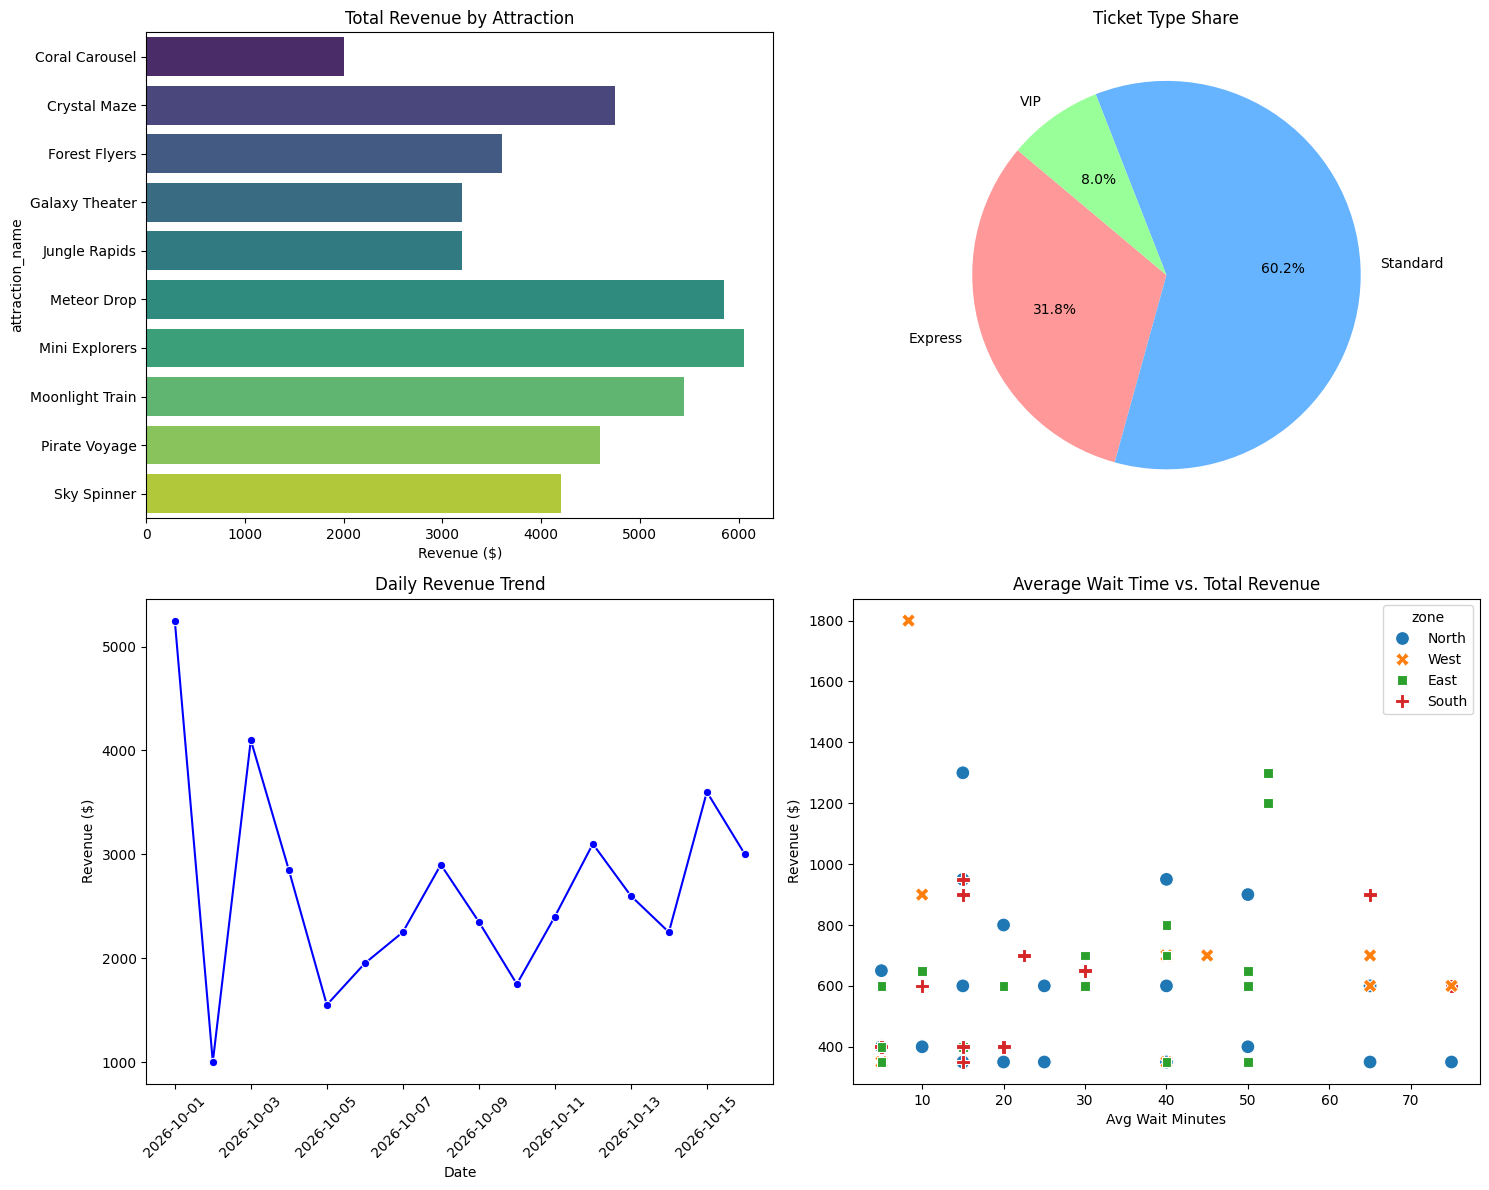

In [0]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Query Gold data into pandas DataFrame
pdf = spark.table("capstone_gold_summary").toPandas()

# Set up 2x2 dashboard canvas
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
plt.subplots_adjust(hspace=0.3, wspace=0.3)

# Chart 1: Bar Chart - Revenue by Attraction
rev_by_attraction = pdf.groupby("attraction_name")["total_revenue"].sum().reset_index()
sns.barplot(data=rev_by_attraction, x="total_revenue", y="attraction_name", ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("Total Revenue by Attraction")
axes[0, 0].set_xlabel("Revenue ($)")

# Chart 2: Pie Chart - Ticket Type Share
ticket_share = pdf.groupby("ticket_type")["completed_entries"].sum()
axes[0, 1].pie(ticket_share, labels=ticket_share.index, autopct="%1.1f%%", startangle=140, colors=["#ff9999","#66b3ff","#99ff99"])
axes[0, 1].set_title("Ticket Type Share")

# Chart 3: Line Chart - Daily Revenue Trend
daily_rev = pdf.groupby("visit_date")["total_revenue"].sum().reset_index()
sns.lineplot(data=daily_rev, x="visit_date", y="total_revenue", marker="o", ax=axes[1, 0], color="b")
axes[1, 0].set_title("Daily Revenue Trend")
axes[1, 0].set_xlabel("Date")
axes[1, 0].set_ylabel("Revenue ($)")
axes[1, 0].tick_params(axis='x', rotation=45)

# Chart 4: Scatter Plot - Avg Wait vs. Revenue
sns.scatterplot(data=pdf, x="avg_wait_time", y="total_revenue", hue="zone", style="zone", s=100, ax=axes[1, 1])
axes[1, 1].set_title("Average Wait Time vs. Total Revenue")
axes[1, 1].set_xlabel("Avg Wait Minutes")
axes[1, 1].set_ylabel("Revenue ($)")

plt.tight_layout()
plt.show()

Catalog/Schema Isolation: Separate environments using dedicated schemas in Unity Catalog (e.g., theme_park_dev vs theme_park_prod).

Pipeline Target Configuration: Configure DLT target pipelines to point to distinct schemas and separate volume storage paths for checkpoints and tables.